In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import time
import joblib

from utils_ML import score_dataset
from utils_preproces import ols_fit, y_distribution_plot, corr_heatmap_plot, make_mi_scores, preprocess_data

from sklearn.ensemble import RandomForestRegressor, VotingRegressor, ExtraTreesRegressor
from xgboost import XGBRegressor, plot_importance
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor


from sklearn.model_selection import train_test_split, StratifiedKFold, KFold


from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import QuantileTransformer

import optuna


import random
from heapq import nsmallest

In [69]:
# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-white")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

In [ ]:
PRETTY_LABELS = {
    "U_lsr":        r"$U_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "V_lsr":        r"$V_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "W_lsr":        r"$W_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UV_lsr":       r"$UV_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UW_lsr":       r"$UW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "VW_lsr":       r"$VW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "UVW_lsr":      r"$UVW_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_U_lsr":    r"$|U|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "abs_W_lsr":    r"$|W|_{\mathrm{LSR}}\,[\mathrm{km\,s^{-1}}]$",
    "P_gal":        r"$P_{\mathrm{gal}}\,[\%]$",
    "rapo":         r"$R_{\mathrm{apo}}\,[\mathrm{kpc}]$",
    "rperi":        r"$R_{\mathrm{peri}}\,[\mathrm{kpc}]$",
    "zmax":         r"$Z_{\max}\,[\mathrm{kpc}]$",
    "eccentricity": r"$e$",
    "R_mean":       r"$R_{\mathrm{mean}}\,[\mathrm{kpc}]$",
}

In [71]:
# Fix random state
random_state = 42

In [72]:
harps = pd.read_csv('harps_final_for_feh.csv')
apogee = pd.read_csv('apogee_final_for_feh.csv')
galah = pd.read_csv('galah_final_for_feh.csv')


print (f'harps contains {len(harps)} stars')
print (f'apogee contains {len(apogee)} stars')    
print (f'galah contains {len(galah)} stars')

harps contains 798 stars
apogee contains 45727 stars
galah contains 71591 stars


### Spliting data into Trianing and Testing sets

In [73]:
# Split APOGEE
apogee_train_full, apogee_test = train_test_split(apogee, test_size=0.1, random_state=random_state)
X_apogee_train = apogee_train_full.drop(columns=['fe_h'])
y_apogee_train = apogee_train_full['fe_h']
X_apogee = apogee.drop(columns=['fe_h'])
y_apogee = apogee['fe_h']
X_apogee_test = apogee_test.drop(columns=['fe_h'])
y_apogee_test = apogee_test['fe_h']

# Split GALAH
galah_train_full, galah_test = train_test_split(galah, test_size=0.1, random_state=random_state)
X_galah_train = galah_train_full.drop(columns=['fe_h'])
y_galah_train = galah_train_full['fe_h']
X_galah = galah.drop(columns=['fe_h'])
y_galah = galah['fe_h']
X_galah_test = galah_test.drop(columns=['fe_h'])
y_galah_test = galah_test['fe_h']


# HARPS — no split
X_harps = harps.drop(columns=['fe_h'])
y_harps = harps['fe_h']

# Combine APOGEE and GALAH train sets
X_combined_train = pd.concat([X_apogee_train, X_galah_train], ignore_index=True)
y_combined_train = pd.concat([y_apogee_train, y_galah_train], ignore_index=True)

# Combine APOGEE and GALAH sets
X_combined = pd.concat([X_apogee, X_galah], ignore_index=True)
y_combined = pd.concat([y_apogee, y_galah], ignore_index=True)

full_df = pd.concat([apogee, galah, harps], ignore_index=True)
X_full = full_df.drop(columns=['fe_h'])
y_full = full_df['fe_h']

In [74]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold
import numpy as np
import time

def model_test_CV_models(X, y, models, k=5, random_state=42):
    """
    Perform k-fold cross-validation for multiple models.
    Returns mean and std of RMSE, MAE, and R2.
    """
    kf = KFold(n_splits=k, shuffle=True, random_state=random_state)
    results = {}

    for name, model in models.items():
        print(f"Scoring model: {name}")
        start_time = time.time()

        rmse_scores = []
        mae_scores = []
        r2_scores = []

        for train_index, test_index in kf.split(X, y):
            X_train, X_test = X.iloc[train_index], X.iloc[test_index]
            y_train, y_test = y.iloc[train_index], y.iloc[test_index]


            model.fit(X_train, y_train)
            y_pred = model.predict(X_test)

            rmse = np.sqrt(mean_squared_error(y_test, y_pred))
            mae = mean_absolute_error(y_test, y_pred)
            r2 = r2_score(y_test, y_pred)

            rmse_scores.append(rmse)
            mae_scores.append(mae)
            r2_scores.append(r2)

        elapsed_time = time.time() - start_time

        results[name] = {
            'mean_rmse': np.mean(rmse_scores),
            'std_rmse': np.std(rmse_scores),
            'mean_mae': np.mean(mae_scores),
            'mean_r2': np.mean(r2_scores),
            'time_sec': elapsed_time
        }

        print(
            f"{name} → "
            f"RMSE: {results[name]['mean_rmse']:.3f} ± {results[name]['std_rmse']:.3f} | "
            f"MAE: {results[name]['mean_mae']:.3f} | "
            f"R²: {results[name]['mean_r2']:.3f} "
            f"({elapsed_time:.2f}s)\n"
        )

    return results

In [75]:
lgbr = LGBMRegressor(random_state=random_state, verbosity=-1, n_jobs=-1, objective="huber")
catbr = CatBoostRegressor(random_state=random_state, verbose=False, thread_count=-1)




model_names = {
    'lgbr': lgbr,
    'catr': catbr,
}


In [106]:
best_features = [x for x in X_apogee.columns]

baseline_results = model_test_CV_models(X_apogee[best_features], y_apogee, model_names, k=5)

for name, score in baseline_results.items():
    print(f"{name:8s} | RMSE: {score['mean_rmse']:.3f} ± {score['std_rmse']:.3f}")


Scoring model: lgbr
lgbr → RMSE: 0.199 ± 0.001 | MAE: 0.156 | R²: 0.412 (2.17s)

Scoring model: catr
catr → RMSE: 0.200 ± 0.001 | MAE: 0.157 | R²: 0.411 (21.65s)

lgbr     | RMSE: 0.199 ± 0.001
catr     | RMSE: 0.200 ± 0.001


# Hyperparameter tunning

In [77]:
import numpy as np
import optuna
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
from sklearn.base import clone

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def cv_rmse(model, X, y, cv):
    scores = []
    for tr, te in cv.split(X, y):
        m = clone(model)
        m.fit(X.iloc[tr], y.iloc[tr])
        pred = m.predict(X.iloc[te])
        scores.append(rmse(y.iloc[te], pred))
    return float(np.mean(scores)), float(np.std(scores))


cv = KFold(n_splits=5, shuffle=True, random_state=random_state)

## Optuna tuning for LightGBM (RMSE)

In [ ]:
from lightgbm import LGBMRegressor

def objective_lgbm(trial, X, y, cv, random_state=42):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),

        "num_leaves": trial.suggest_int("num_leaves", 16, 256),
        "max_depth": trial.suggest_int("max_depth", -1, 16),
        "min_child_samples": trial.suggest_int("min_child_samples", 5, 200),

        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),

        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 50.0, log=True),

        "random_state": random_state,
        "n_jobs": -1,
        "verbosity": -1,
    }

    model = LGBMRegressor(**params)
    mean_rmse, _ = cv_rmse(model, X, y, cv)
    return mean_rmse

study_lgbm = optuna.create_study(direction="minimize", study_name="LGBM_RMSE")
study_lgbm.optimize(lambda t: objective_lgbm(t, X_apogee, y_apogee, cv, random_state), n_trials=1)

print("Best LGBM RMSE:", study_lgbm.best_value)
print("Best LGBM params:", study_lgbm.best_params)

#best_lgbm = LGBMRegressor(**study_lgbm.best_params, random_state=random_state, n_jobs=-1, verbosity=-1)

[I 2026-03-03 16:38:08,474] A new study created in memory with name: LGBM_RMSE
[I 2026-03-03 16:38:38,312] Trial 0 finished with value: 0.19913572908178873 and parameters: {'n_estimators': 1549, 'learning_rate': 0.015559433511114745, 'num_leaves': 183, 'max_depth': 4, 'min_child_samples': 57, 'subsample': 0.6725015784456961, 'colsample_bytree': 0.5569142474140696, 'reg_alpha': 0.002194279326611787, 'reg_lambda': 0.00010034359452194833}. Best is trial 0 with value: 0.19913572908178873.
[I 2026-03-03 16:40:03,652] Trial 1 finished with value: 0.20329057513069268 and parameters: {'n_estimators': 664, 'learning_rate': 0.037887826196364154, 'num_leaves': 134, 'max_depth': 16, 'min_child_samples': 64, 'subsample': 0.5687341878339263, 'colsample_bytree': 0.8526093452237831, 'reg_alpha': 9.858375246118024e-06, 'reg_lambda': 0.037163450002799046}. Best is trial 0 with value: 0.19913572908178873.
[I 2026-03-03 16:41:16,220] Trial 2 finished with value: 0.20346341897699402 and parameters: {'n_est

Best LGBM RMSE: 0.19889204211986336
Best LGBM params: {'n_estimators': 733, 'learning_rate': 0.011467157750218542, 'num_leaves': 29, 'max_depth': 5, 'min_child_samples': 127, 'subsample': 0.7982121372515886, 'colsample_bytree': 0.6257975813765977, 'reg_alpha': 1.925052260757468e-06, 'reg_lambda': 0.0031461610475686788}


In [ ]:
#best_lgbm.fit(X_apogee, y_apogee)
#joblib.dump(best_lgbm, "best_lgbm.pkl")
best_lgbm = joblib.load("best_lgbm.pkl")

## Optuna tuning for CatBoost (RMSE)

In [ ]:
from catboost import CatBoostRegressor

def objective_cat(trial, X, y, cv, random_state=42):
    params = {
        "iterations": trial.suggest_int("iterations", 50, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),
        "depth": trial.suggest_int("depth", 4, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 50.0, log=True),

        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "random_strength": trial.suggest_float("random_strength", 1e-3, 10.0, log=True),
        "bagging_temperature": trial.suggest_float("bagging_temperature", 0.0, 5.0),

        "loss_function": "RMSE",
        "random_seed": random_state,
        "verbose": False,
        "thread_count": -1,
    }

    model = CatBoostRegressor(**params)
    mean_rmse, _ = cv_rmse(model, X, y, cv)
    return mean_rmse

study_cat = optuna.create_study(direction="minimize", study_name="CAT_RMSE")
study_cat.optimize(lambda t: objective_cat(t, X_apogee, y_apogee, cv, random_state), n_trials=1)

print("Best CatBoost RMSE:", study_cat.best_value)
print("Best CatBoost params:", study_cat.best_params)

#best_cat = CatBoostRegressor(**study_cat.best_params, loss_function="RMSE",
#                             random_seed=random_state, verbose=False, thread_count=-1)

[I 2026-03-03 17:13:01,755] A new study created in memory with name: CAT_RMSE
[I 2026-03-03 17:13:41,253] Trial 0 finished with value: 0.19946137406919157 and parameters: {'iterations': 1846, 'learning_rate': 0.03778688264854384, 'depth': 7, 'l2_leaf_reg': 14.233003264262514, 'subsample': 0.5209127734187817, 'random_strength': 0.10337721025536585, 'bagging_temperature': 2.7845146763660105}. Best is trial 0 with value: 0.19946137406919157.
[I 2026-03-03 17:14:04,097] Trial 1 finished with value: 0.19943869603694564 and parameters: {'iterations': 1855, 'learning_rate': 0.08047966851228432, 'depth': 4, 'l2_leaf_reg': 14.997022392819904, 'subsample': 0.5349063706181811, 'random_strength': 0.050745700222273885, 'bagging_temperature': 3.847654900880641}. Best is trial 1 with value: 0.19943869603694564.
[I 2026-03-03 17:14:51,565] Trial 2 finished with value: 0.20484589781757764 and parameters: {'iterations': 1488, 'learning_rate': 0.1184547463432529, 'depth': 8, 'l2_leaf_reg': 3.489845714970

Best CatBoost RMSE: 0.1985519012757046
Best CatBoost params: {'iterations': 1478, 'learning_rate': 0.014258691339243105, 'depth': 7, 'l2_leaf_reg': 30.6531924619589, 'subsample': 0.8632405358997681, 'random_strength': 1.6582128849491768, 'bagging_temperature': 2.9143724563128672}


In [ ]:
#best_cat.fit(X_apogee, y_apogee)
#joblib.dump(best_cat, "best_cat.pkl")
best_cat = joblib.load("best_cat.pkl")

## XGBoost (3.0.2) + Optuna (no early stopping)

In [80]:
from xgboost import XGBRegressor

def objective_xgb(trial, X, y, cv, random_state=42):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 50, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.2, log=True),

        "max_depth": trial.suggest_int("max_depth", 3, 12),
        "min_child_weight": trial.suggest_float("min_child_weight", 1e-2, 50.0, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),

        "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
        "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 50.0, log=True),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),

        "objective": "reg:squarederror",
        "tree_method": "hist",
        "random_state": random_state,
        "n_jobs": -1,
        "verbosity": 0,
    }

    model = XGBRegressor(**params)
    mean_rmse, _ = cv_rmse(model, X, y, cv)
    return mean_rmse

study_xgb = optuna.create_study(direction="minimize", study_name="XGB_RMSE")
study_xgb.optimize(lambda t: objective_xgb(t, X_apogee, y_apogee, cv, random_state), n_trials=100)

print("Best XGB RMSE:", study_xgb.best_value)
print("Best XGB params:", study_xgb.best_params)

best_xgb = XGBRegressor(**study_xgb.best_params, objective="reg:squarederror",
                        tree_method="hist", random_state=random_state, n_jobs=-1, verbosity=0)

[I 2026-03-03 18:32:52,194] A new study created in memory with name: XGB_RMSE
[I 2026-03-03 18:32:57,514] Trial 0 finished with value: 0.20130732624074404 and parameters: {'n_estimators': 613, 'learning_rate': 0.0070421461762209805, 'max_depth': 5, 'min_child_weight': 0.02472917663611967, 'subsample': 0.9567245699598909, 'colsample_bytree': 0.9593760991957511, 'reg_alpha': 1.9534430774049157e-08, 'reg_lambda': 1.1915029131872244e-06, 'gamma': 3.0596280682905945}. Best is trial 0 with value: 0.20130732624074404.
[I 2026-03-03 18:33:02,869] Trial 1 finished with value: 0.19931953015046655 and parameters: {'n_estimators': 1137, 'learning_rate': 0.05297764593870873, 'max_depth': 6, 'min_child_weight': 0.18881864382661223, 'subsample': 0.9583371600900332, 'colsample_bytree': 0.5014221727753982, 'reg_alpha': 0.5002004605295651, 'reg_lambda': 3.8913773210512705e-08, 'gamma': 0.1106750951973462}. Best is trial 1 with value: 0.19931953015046655.
[I 2026-03-03 18:33:04,629] Trial 2 finished with

Best XGB RMSE: 0.19875014016992515
Best XGB params: {'n_estimators': 1335, 'learning_rate': 0.00556704569159556, 'max_depth': 9, 'min_child_weight': 1.6640217841420348, 'subsample': 0.7167229433933807, 'colsample_bytree': 0.9598188842295867, 'reg_alpha': 0.0007975246507314437, 'reg_lambda': 3.151620045129353e-08, 'gamma': 0.2598941207874676}


In [ ]:
#best_xgb.fit(X_apogee, y_apogee)
#joblib.dump(best_xgb, "best_xgb.pkl")
best_xgb = joblib.load("best_xgb.pkl")
best_xgb

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.9598188842295867
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [109]:
def evaluate_on_test_data(X_train, y_train, test_df, target, models, test_name='Test'):
    """
    Trains models on the full training set and evaluates on a test set.

    Parameters:
        X_train, y_train: Training features and target.
        test_df: DataFrame containing the test data (including the target column).
        target (str): Name of the target column in test_df.
        models: Dictionary of model_name: model_instance.
        test_name (str): Label for this test set (e.g., 'Apogee', 'HARPS').

    Returns:
        dict: model_name → test MAE and baseline MAE
    """
    X_test = test_df.drop(columns=[target])
    y_test = test_df[target]

    results = {}

    for name, model in models.items():
        print(f"Training and evaluating {name} on {test_name}")
        model.fit(X_train, y_train)

        y_pred = model.predict(X_test)

        mae_model = mean_absolute_error(y_test, y_pred)
        rmse_model = np.sqrt(mean_squared_error(y_test, y_pred))
        mae_baseline = mean_absolute_error(y_test, [y_test.mean()] * len(y_test))
        rmse_baseline = np.sqrt(mean_squared_error(y_test, [y_test.mean()] * len(y_test)))


        results[name] = {
            'rmse_model': rmse_model,
            'rmse_baseline': rmse_baseline
        }

        print(f"{name} | {test_name} RMSE: {rmse_model:.3f} (mean baseline: {rmse_baseline:.3f})\n")

    return results


In [116]:
y_apogee.describe()

count    45727.000000
mean        -0.239522
std          0.260048
min         -1.000000
25%         -0.430000
50%         -0.250000
75%         -0.050000
max          0.560000
Name: fe_h, dtype: float64

In [115]:
harps.fe_h.describe()

count    798.000000
mean      -0.114862
std        0.259546
min       -0.980000
25%       -0.260000
50%       -0.090000
75%        0.070000
max        0.410000
Name: fe_h, dtype: float64

In [118]:
best_model_names = {
    'xgbr': best_xgb,
    'lgbm': best_lgbm,
}

# Evaluate on HARPS test
results_apogee = evaluate_on_test_data(
    X_apogee, y_apogee,
    test_df=harps,
    target='fe_h',
    models=best_model_names,
    test_name='Apogee'
)


Training and evaluating xgbr on Apogee
xgbr | Apogee RMSE: 0.224 (mean baseline: 0.259)

Training and evaluating lgbm on Apogee
lgbm | Apogee RMSE: 0.224 (mean baseline: 0.259)



In [124]:
import matplotlib.pyplot as plt
import numpy as np

def plot_residuals_vs_true(y_true, y_pred, model_name='Model', sample_name='Test Set'):
    """
    Plot residuals (y_true - y_pred) vs y_true, and residuals from predicting the mean.

    Parameters:
        y_true: Ground truth target values.
        y_pred: Model predictions.
        model_name: Name of the model for labeling.
        sample_name: Name of the dataset (e.g., 'Apogee' or 'HARPS').
    """
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_mean = np.full_like(y_true, y_true.mean())

    residuals_model = y_true - y_pred
    residuals_mean = y_true - y_mean

    plt.figure(figsize=(10, 6))
    plt.scatter(y_true, residuals_model, alpha=0.6, label=f'{model_name}', s=20)
    #plt.scatter(y_true, residuals_mean, alpha=0.4, label='Mean predictor', s=20, marker='x')

    plt.axhline(0, color='gray', linestyle='--')
    plt.xlabel('True Value (y)')
    plt.ylabel('Residual (y_true - y_pred)')
    plt.title(f'Residuals vs True Values ({sample_name})')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


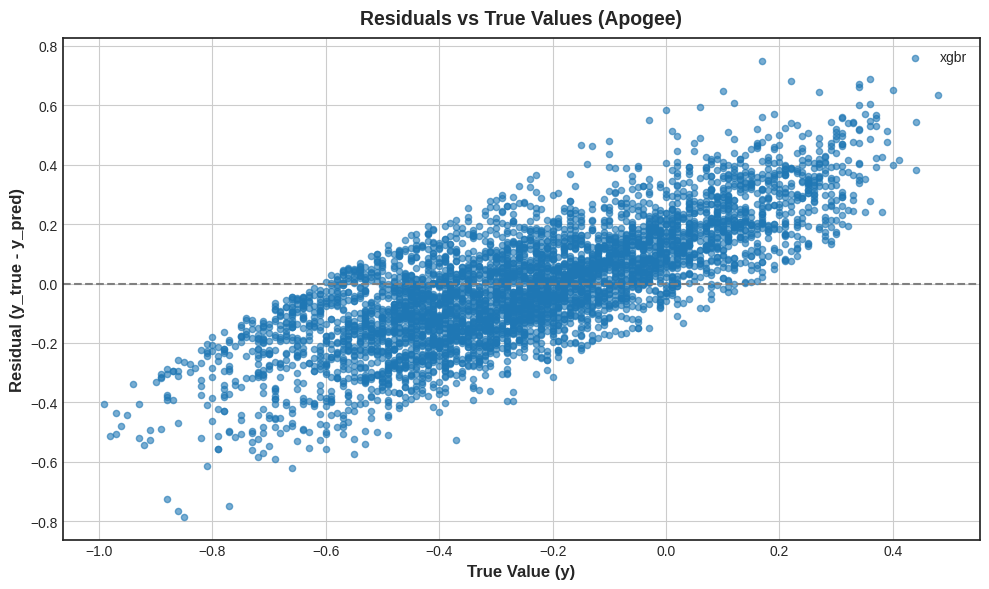

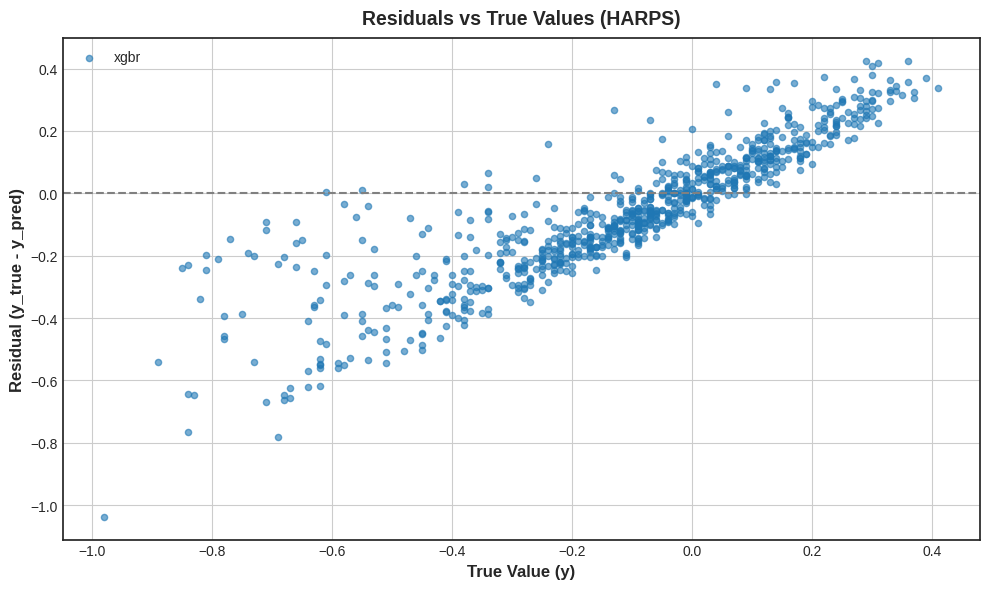

In [126]:
# Example for one model and one test set
best_model_name = 'xgbr'
model = best_model_names[best_model_name]
model.fit(X_combined_train, y_combined_train)

y_pred_apogee = model.predict(X_apogee_test)
plot_residuals_vs_true(y_apogee_test, y_pred_apogee, model_name=best_model_name, sample_name='Apogee')

y_pred_harps = model.predict(X_harps)
plot_residuals_vs_true(y_harps, y_pred_harps, model_name=best_model_name, sample_name='HARPS')

#y_pred_galah = model.predict(X_galah_test)
#plot_residuals_vs_true(y_galah_test, y_pred_galah, model_name=best_model_name, sample_name='GALAH')


In [140]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

def two_panel_pred_resid_with_mean(
    y_true,
    y_pred,
    model_name="Model",
    sample_name="Sample",
    gridsize=20,
    bins=100,
    cmap="viridis",
    save_path=None,
    add_colorbar=True
):
    """
    Two-panel figure:
      (a) y_pred vs y_true with 1:1 line and mean-predictor reference
      (b) residuals vs y_true with median trend and ±1σ envelope
    Includes metrics for model and mean predictor.

    y_true, y_pred: arrays or Series in dex.
    """

    y_true = np.asarray(y_true).astype(float)
    y_pred = np.asarray(y_pred).astype(float)

    # Mean predictor
    y_mean = np.full_like(y_true, np.mean(y_true))

    # Metrics
    resid_model = y_true - y_pred
    resid_mean  = y_true - y_mean

    rmse_model = np.sqrt(np.mean(resid_model**2))
    rmse_mean  = np.sqrt(np.mean(resid_mean**2))

    sigma_y = np.std(y_true)
    r2_model = 1.0 - (rmse_model**2) / (sigma_y**2) if sigma_y > 0 else np.nan
    r2_mean  = 1.0 - (rmse_mean**2) / (sigma_y**2) if sigma_y > 0 else np.nan  # ~0 by construction

    # Limits (consistent)
    pad = 0.03 * (y_true.max() - y_true.min() + 1e-9)
    x_min, x_max = y_true.min() - pad, y_true.max() + pad
    y_min, y_max = min(y_pred.min(), y_true.min()) - pad, max(y_pred.max(), y_true.max()) + pad

    # Residual y-lims symmetric for aesthetics
    rmax = np.nanpercentile(np.abs(resid_model), 99)
    rmax = max(rmax, np.nanpercentile(np.abs(resid_mean), 99))
    r_lim = 1.05 * rmax

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)

    # -------------------------
    # (a) Predicted vs True
    # -------------------------
    ax = axes[0]
    hb0 = ax.hexbin(y_true, y_pred, gridsize=gridsize, cmap=cmap, mincnt=5)
    ax.plot([x_min, x_max], [x_min, x_max], ls="--", lw=1.2, color="gray", label="1:1")

    # mean predictor shown as horizontal line at <y_true>
    ax.axhline(np.mean(y_true), ls=":", lw=1.5, color="black", label=r"Mean predictor ($\langle y\rangle$)")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.set_xlabel(r"True $\mathrm{[Fe/H]}$ [dex]")
    ax.set_ylabel(r"Predicted $\mathrm{[Fe/H]}$ [dex]")
    ax.set_title(f"{model_name} — {sample_name}")

    ax.text(
        0.02, 0.98,
        rf"$\mathrm{{RMSE}}={rmse_model:.3f}$ dex" "\n" rf"$R^2={r2_model:.3f}$",
        transform=ax.transAxes,
        va="top"
    )

    ax.text(
        0.98, 0.02,
        rf"Mean RMSE={rmse_mean:.3f} dex" "\n" rf"Mean $R^2={r2_mean:.3f}$",
        transform=ax.transAxes,
        ha="right", va="bottom"
    )

    ax.legend(frameon=False, loc="lower right")

    # -------------------------
    # (b) Residuals vs True
    # -------------------------
    ax = axes[1]
    hb1 = ax.hexbin(y_true, resid_model, gridsize=gridsize, cmap=cmap, mincnt=5)

    ax.axhline(0.0, ls="--", lw=1.2, color="gray")
    # mean predictor residuals are simply y_true - mean(y_true); show as reference band:
    # here: draw ±sigma_y (or optionally ±rmse_mean)
    ax.axhline(0.0, ls=":", lw=1.0, color="black")  # redundant but keeps style consistent

    # Running median + ±1σ of residuals (model)
    edges = np.linspace(y_true.min(), y_true.max(), bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])

    med, _, _ = binned_statistic(y_true, resid_model, statistic="median", bins=edges)
    sd,  _, _ = binned_statistic(y_true, resid_model, statistic="std",    bins=edges)

    ax.plot(centers, med, color="black", lw=2, label="Median residual")
    ax.fill_between(centers, med - sd, med + sd, color="black", alpha=0.15, label=r"$\pm1\sigma$")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(-r_lim, r_lim)

    ax.set_xlabel(r"True $\mathrm{[Fe/H]}$ [dex]")
    ax.set_ylabel(r"Residual $\left(\mathrm{[Fe/H]}_{\rm true}-\mathrm{[Fe/H]}_{\rm pred}\right)$ [dex]")
    ax.set_title("Residuals")

    ax.text(
        0.02, 0.98,
        rf"$\mathrm{{RMSE}}={rmse_model:.3f}$ dex" "\n" rf"$R^2={r2_model:.3f}$",
        transform=ax.transAxes,
        va="top"
    )

    # Mean predictor reference: its RMSE equals sigma_y (for centered y), but here we computed rmse_mean
    ax.text(
        0.98, 0.02,
        rf"Mean RMSE={rmse_mean:.3f} dex",
        transform=ax.transAxes,
        ha="right", va="bottom"
    )

    ax.legend(frameon=False, loc="lower right")

    # Optional shared colorbar (use the right panel hb for colorbar)
    if add_colorbar:
        cbar = fig.colorbar(hb1, ax=axes.ravel().tolist(), shrink=0.95)
        cbar.set_label("Number of stars")

    # Save
    if save_path is not None:
        fig.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

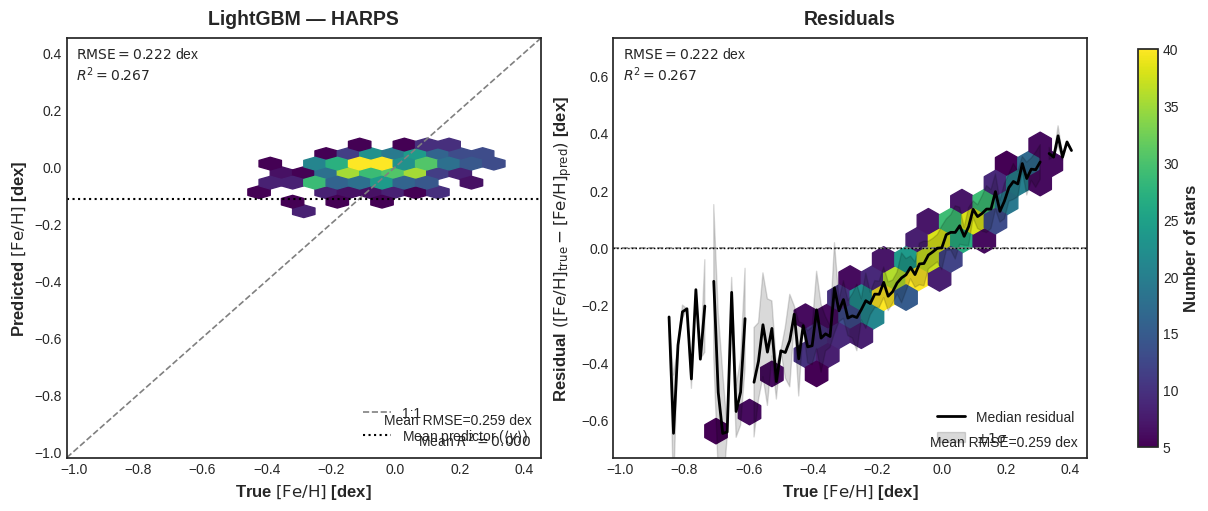

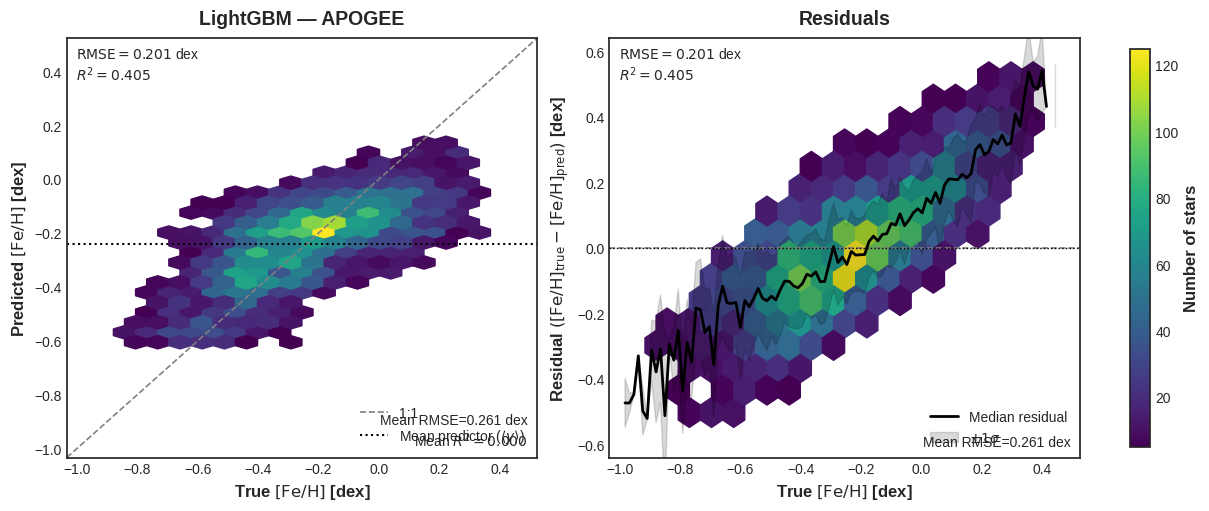

In [143]:
y_pred_harps_lgbm = best_lgbm.predict(X_apogee_test)


best_model_name = 'lgbm'
model = best_model_names[best_model_name]
model.fit(X_apogee_train, y_apogee_train)
y_pred_apogee_lgbm = model.predict(X_apogee_test)



# APOGEE
two_panel_pred_resid_with_mean(
    y_true=y_harps,
    y_pred=y_pred_harps,
    model_name="LightGBM",
    sample_name="HARPS",
    save_path="fig_harps_lgbm_pred_resid.png"
)

# HARPS
two_panel_pred_resid_with_mean(
    y_true=y_apogee_test,
    y_pred=y_pred_apogee_lgbm,
    model_name="LightGBM",
    sample_name="APOGEE",
    save_path="fig_apogee_lgbm_pred_resid.png"
)

In [183]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binned_statistic

def two_panel_scatter_with_mean(
    y_true,
    y_pred,
    model_name="Model",
    sample_name="Sample",
    bins=10,
    marker_size=20,
    alpha=0.25,
    save_path=None,
    color = 'blue'
):
    """
    Two-panel scatter plot showing:
    (a) Predicted vs True
    (b) Residuals vs True
    Includes mean predictor reference and metrics.
    """

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    y_mean = np.mean(y_true)

    residuals = y_true - y_pred
    residuals_mean = y_true - y_mean

    rmse_model = np.sqrt(np.mean(residuals**2))
    rmse_mean = np.sqrt(np.mean(residuals_mean**2))
    sigma_y = np.std(y_true)

    r2_model = 1 - (rmse_model**2 / sigma_y**2)

    # Axis limits
    pad = 0.02 * (y_true.max() - y_true.min())
    xmin, xmax = y_true.min() - pad, y_true.max() + pad
    ymin, ymax = xmin, xmax

    rmax = np.percentile(np.abs(residuals), 99)
    rlim = 1.1 * rmax

    fig, axes = plt.subplots(1, 2, figsize=(7, 3), constrained_layout=True)

    # --------------------------
    # (a) Predicted vs True
    # --------------------------
    ax = axes[0]

    ax.scatter(y_true, y_pred, s=marker_size, alpha=alpha, color=color)

    # 1:1 line
    ax.plot([xmin, xmax], [xmin, xmax], ls=":", color="gray", lw=2)

    # Mean predictor (horizontal line)
    #ax.axhline(y_mean, ls=":", color="black", lw=1.5)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

    ax.set_xlabel(r"True $\mathrm{[Fe/H]}$ [dex]")
    ax.set_ylabel(r"Predicted $\mathrm{[Fe/H]}$ [dex]")

    #ax.set_title(f"{model_name} — {sample_name}")

    ax.text(
        0.02, 0.98,
        rf"$\mathrm{{RMSE}}={rmse_model:.3f}$ dex" "\n"
        rf"$R^2={r2_model:.3f}$",
        transform=ax.transAxes,
        va="top"
    )

    ax.text(
        0.98, 0.02,
        rf"Mean RMSE={rmse_mean:.3f} dex",
        transform=ax.transAxes,
        ha="right",
        va="bottom"
    )

    # --------------------------
    # (b) Residuals vs True
    # --------------------------
    ax = axes[1]

    ax.scatter(y_true, residuals, s=marker_size, alpha=alpha, color=color)

    ax.axhline(0, ls="--", color="gray", lw=2)

    # Running median
    edges = np.linspace(y_true.min(), y_true.max(), bins + 1)
    centers = 0.5 * (edges[:-1] + edges[1:])
    medians, _, _ = binned_statistic(y_true, residuals, statistic="median", bins=edges)

    #ax.plot(centers, medians, color="black", lw=2)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(-rlim, rlim)

    ax.set_xlabel(r"True $\mathrm{[Fe/H]}$ [dex]")
    ax.set_ylabel(r"Residual ($\mathrm{true}-\mathrm{pred}$) [dex]")

    #ax.set_title("Residuals")

    #ax.text(
    #    0.02, 0.98,
    #    rf"$\mathrm{{RMSE}}={rmse_model:.3f}$ dex",
    #    transform=ax.transAxes,
    #    va="top"
    #)

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

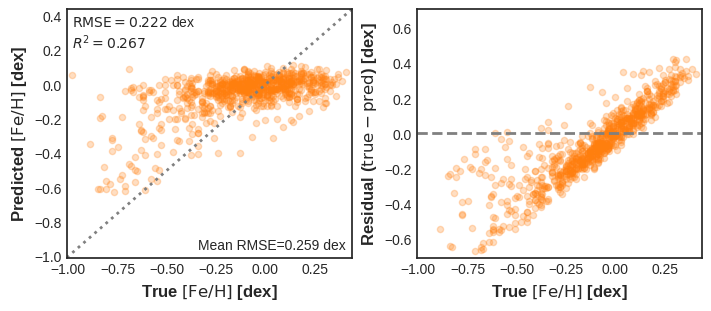

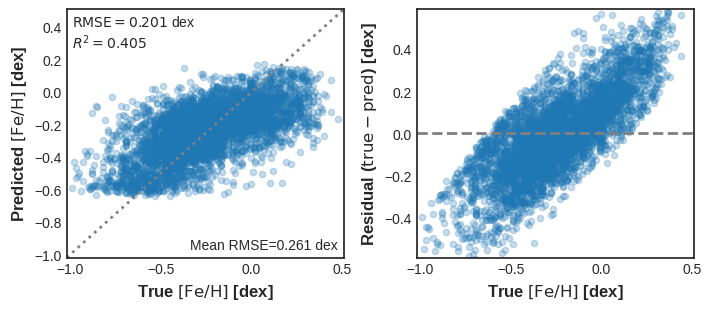

In [184]:
y_pred_harps_lgbm = best_lgbm.predict(X_apogee_test)


best_model_name = 'lgbm'
model = best_model_names[best_model_name]
model.fit(X_apogee_train, y_apogee_train)
y_pred_apogee_lgbm = model.predict(X_apogee_test)

# color_list_2 = ["#1f77b4", "#ff7f0e"]  # APOGEE, HARPS


# APOGEE
two_panel_scatter_with_mean(
    y_true=y_harps,
    y_pred=y_pred_harps,
    model_name="LightGBM",
    sample_name="HARPS",
    save_path="fig_harps_lgbm_pred_resid_scatter.png",
    color = '#ff7f0e'
)

# HARPS
two_panel_scatter_with_mean(
    y_true=y_apogee_test,
    y_pred=y_pred_apogee_lgbm,
    model_name="LightGBM",
    sample_name="APOGEE",
    save_path="fig_apogee_lgbm_pred_resid_scatter.png",
    color = '#1f77b4'
)